## 1. Setup, Data & the 80/20 Split

Imports the libraries, sets the settings, loads the two training collections and splits each one into 80% for training and 20% held back for testing, then loads the external spam and ham.

**Why a split?** A model can memorise its training emails and look perfect on them. Only mail it has never seen tells us how good it really is. The split is *stratified* (each part keeps the same spam share) and uses a fixed *seed* (`42`), so everybody who runs the notebook gets the same split.

### 1.1 Imports & Environment
Imports the standard-library, scikit-learn, pandas and plotting tools used in the rest of the notebook.

In [1]:
# --- Standard library (ships with Python) ---
import hashlib       # SHA-256 fingerprints of files
import os            # read environment variables such as RETRAIN
import re            # regular expressions: pattern matching on text
import sys           # used once, to print the Python version
from pathlib import Path   # file paths that work on Windows, macOS and Linux

# --- Third-party libraries ---
import joblib                          # save and load trained models
import matplotlib.pyplot as plt        # draw figures
import numpy as np                     # fast arrays of numbers
import pandas as pd                    # tables ("DataFrames")
import sklearn                         # scikit-learn: the machine-learning toolkit (imported whole to print its version)
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer   # text -> numbers
from sklearn.linear_model import LogisticRegression                            # classifier 1 of 3 (the other two are below)
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)           # scoring functions
from sklearn.model_selection import GridSearchCV, train_test_split             # tuning and splitting
from sklearn.naive_bayes import MultinomialNB                                  # classifier 2 of 3
from sklearn.pipeline import Pipeline                                          # chain "text -> numbers -> decision"
from sklearn.svm import LinearSVC                                              # classifier 3 of 3: the linear SVM

### 1.2 Settings
Sets the folder paths, the random seed (`42`), the split size, the cross-validation folds, the artefact-filter thresholds, the number of bootstrap resamples and the run mode (`RETRAIN` / `WRITE`), then prints the mode and library versions.

In [2]:
# --- Settings: everything you might want to change is in this one cell ---

# Folders (paths are relative to the notebooks/ folder)
TRAIN_DIR = Path("../data/train/champa")      # the Enron and SpamAssassin training CSV files
PROC = Path("../data/processed")              # cleaned traced spam and Apache ham
MODEL_DIR = Path("../models")                 # the saved, verified models
RETRAIN_DIR = Path("../models_retrain")       # where RETRAIN=1 writes its models
RESULTS = Path("../results")                  # tables written by the first run
FIGS = Path("../figures")                     # figures for the report

SEED = 42            # fixed random seed: same split, same bootstrap, same results every time
TEST_SIZE = 0.2      # 20% of each collection is held out for testing
CV_FOLDS = 3         # cross-validation folds used when tuning
RATIO, MIN_DOCS = 10, 10   # source-artefact filter (section 3): a word is flagged if one corpus uses it 10x more often
N_BOOT = 2000        # number of bootstrap resamples (section 7)

# RETRAIN=1 in the environment means "retrain from scratch and write nothing".
RETRAIN = os.environ.get("RETRAIN", "0") == "1"
WRITE = not RETRAIN  # in the normal mode we are allowed to (re)write results and figures

print("mode:", "RETRAIN (writes nothing)" if RETRAIN else "load saved models and verify")
print("python", sys.version.split()[0], "| scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

mode: load saved models and verify
python 3.12.0 | scikit-learn 1.9.0 | numpy 2.5.4 | pandas 3.1.0


### 1.3 Load Corpora & Split
Loads the Enron and SpamAssassin training CSVs, splits each 80/20 (stratified, seed 42), combines and shuffles the two training parts, and loads the cleaned external spam (1,742) and Apache ham (1,720).

In [3]:
def load_corpus(filename, corpus):
    """Read one training CSV and return a table with three columns:
    text (subject + body joined), label (1 = spam, 0 = ham) and corpus (its name).
    The CSV has other columns (sender, urls, ...); we ignore them because they identify the source, not the content."""
    table = pd.read_csv(TRAIN_DIR / filename)
    table["text"] = table["subject"].fillna("") + " " + table["body"].fillna("")
    assert set(table["label"].unique()) <= {0, 1}     # stop if a label is anything other than 0 or 1
    table["corpus"] = corpus
    return table[["text", "label", "corpus"]]


def split(table):
    """Stratified 80/20 split with a fixed seed. Returns (train part, held-out part)."""
    return train_test_split(table, test_size=TEST_SIZE, stratify=table["label"], random_state=SEED)


enron_train, enron_test = split(load_corpus("Enron.csv", "enron"))
sa_train, sa_test = split(load_corpus("SpamAssasin.csv", "spamassassin"))   # (sic) the file name is spelled this way

# Combine the two training parts and shuffle them, so every cross-validation fold mixes both collections.
train = pd.concat([enron_train, sa_train], ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)

# External data: cleaned text only (built by scripts/build_traced_set.py and scripts/build_ham_apache.py).
# dtype=str keeps ids such as "s001" as text; keep_default_na=False stops empty text turning into NaN.
spam_ext = pd.read_csv(PROC / "traced_all.csv", dtype=str, keep_default_na=False)
ham_ext = pd.read_csv(PROC / "ham_apache.csv", dtype=str, keep_default_na=False)
assert len(spam_ext) == 1742 and len(ham_ext) == 1720   # fail loudly if the data is not what we expect

### 1.4 Data Overview
Shows the number of emails and the spam share in each part.

In [4]:
# A quick look at what we have: how many emails in each part, and what share of each is spam.
parts = {"Enron train": enron_train, "SpamAssassin train": sa_train, "Combined train": train,
         "Enron held-out": enron_test, "SpamAssassin held-out": sa_test}
overview = pd.DataFrame({
    "emails": [len(part) for part in parts.values()] + [len(spam_ext), len(ham_ext)],
    "spam share": [round(part["label"].mean(), 3) for part in parts.values()] + [1.0, 0.0],
}, index=list(parts) + ["External spam (traced)", "External ham (Apache)"])
overview

,emails,spam share
Enron train,23813,0.470
SpamAssassin train,4647,0.296
Combined train,28460,0.441
Enron held-out,5954,0.469
SpamAssassin held-out,1162,0.296
External spam (traced),1742,1.000
External ham (Apache),1720,0.000


## 2. Preprocessing: Masking

Cleans every email's text with one function, `mask()`, before the model sees it. It

1. makes everything lowercase,
2. removes a short list of words that identify *which collection* an email came from rather than whether it is spam (`enron`, `mailman`, `linux`, ...), and
3. removes all digits (this also removes years such as 2002, which would give away the collection).

**Why:** if every Enron email contains the word "enron", a model can learn "enron means ham". That is useless on new mail. The same function is applied to training, held-out and external text, so nothing is treated differently.

### 2.1 Masking Function
Defines the artefact-word list and `mask()` and tries it on a made-up example.

In [5]:
# Words that tell the model where a message came from, not what it is.
ARTEFACT_WORDS = [
    "enron", "ect", "hou", "hpl", "houston",                         # Enron-specific
    "mailman", "listinfo", "sourceforge", "spamassassin", "razor",   # mailing-list / SpamAssassin-specific
    "exmh", "ilug", "linux", "wrote",
]
# One regular expression that matches any of them as a whole word (\b = word boundary).
ARTEFACT_PATTERN = re.compile(r"\b(" + "|".join(ARTEFACT_WORDS) + r")\b")


def mask(text):
    """Lowercase, remove artefact words and digits, and collapse repeated whitespace."""
    text = text.lower()
    text = ARTEFACT_PATTERN.sub(" ", text)     # replace artefact words with a space
    text = re.sub(r"\d+", " ", text)           # replace every run of digits with a space
    text = re.sub(r"\s+", " ", text)           # collapse runs of spaces / newlines into one space
    return text.strip()


# Try it on a made-up example to see what it does:
mask("Hello from ENRON, Houston! Call 555-0199 before 2001.")

'hello from , ! call - before .'

### 2.2 Apply Masking
Applies `mask()` to the training and held-out text, the external spam and both ham variants (`primary` and `stripped`).

In [6]:
# Apply mask() to every text the models will see, and store the result in a new column called "clean".
for part in (train, enron_test, sa_test):
    part["clean"] = part["text"].map(mask)

spam_clean = spam_ext["text"].map(mask)
ham_clean = {
    "primary": ham_ext["text"].map(mask),            # the ham text as extracted (same pipeline as the spam)
    "stripped": ham_ext["text_stripped"].map(mask),  # the ham with quoted replies and list footers removed (sensitivity check)
}

## 3. Preprocessing: Source-Artefact Words (Training Split Only)

**The problem.** Legitimate mail from two different sources should look alike *as ham*. But a word that is common in Enron ham and almost absent from SpamAssassin ham (or the reverse) tells the model *where the mail came from*, not whether it is spam. The model would learn a shortcut that fails on new mail.

**The fix, step by step.**

1. For every word, work out the share of Enron ham emails containing it and the share of SpamAssassin ham emails containing it (adding 1 to each count so we never divide by zero).
2. Divide one share by the other.
3. If the ratio is 10 or more in either direction (`RATIO`), the word is an **artefact**. Words appearing in fewer than 10 ham emails (`MIN_DOCS`) are ignored: too rare to judge.
4. The artefact words become TF-IDF *stop words*, which means the models never see them.

Only the training split is used here. No held-out or external data leaks into this step.

### 3.1 Find Source-Artefact Words
Defines `find_source_artefacts()` and runs it on the training split, printing how many candidate words are flagged.

In [7]:
def find_source_artefacts(train_df, ratio=RATIO, min_docs=MIN_DOCS):
    """Return a table with one row per candidate word and a True/False column 'artefact'."""
    # Look only at ham, split by which corpus it came from.
    ham = train_df[train_df["label"] == 0]
    enron_ham = ham.loc[ham["corpus"] == "enron", "clean"]
    sa_ham = ham.loc[ham["corpus"] == "spamassassin", "clean"]

    # Count in how many emails each word appears (binary=True: once per email, however often it occurs).
    vectorizer = CountVectorizer(binary=True, min_df=min_docs)
    counts = vectorizer.fit_transform(pd.concat([enron_ham, sa_ham]))
    n_enron = len(enron_ham)
    docs_enron = np.asarray(counts[:n_enron].sum(axis=0)).ravel()    # first rows are the Enron emails
    docs_sa = np.asarray(counts[n_enron:].sum(axis=0)).ravel()       # the rest are SpamAssassin

    # Share of each corpus's ham that contains the word, with +1 smoothing.
    share_enron = (docs_enron + 1) / (len(enron_ham) + 2)
    share_sa = (docs_sa + 1) / (len(sa_ham) + 2)

    table = pd.DataFrame({"word": vectorizer.get_feature_names_out(),
                          "enron_ham_docs": docs_enron,
                          "sa_ham_docs": docs_sa,
                          "enron_to_sa_ratio": share_enron / share_sa})
    # An artefact if one corpus uses the word at least `ratio` times more than the other.
    table["artefact"] = (table["enron_to_sa_ratio"] >= ratio) | (table["enron_to_sa_ratio"] <= 1 / ratio)
    return table


artefact_table = find_source_artefacts(train)
SOURCE_ARTEFACTS = sorted(artefact_table.loc[artefact_table["artefact"], "word"])
print(f"{len(artefact_table):,} candidate words, {len(SOURCE_ARTEFACTS):,} flagged as source artefacts")

flagged = artefact_table[artefact_table["artefact"]]
if WRITE:
    flagged.sort_values("enron_ham_docs", ascending=False).to_csv(RESULTS / "source_artefact_words.csv", index=False)

12,974 candidate words, 1,889 flagged as source artefacts


### 3.2 Example Artefact Words
Lists the most common flagged words from each side.

In [8]:
# The most common flagged words from each side, to see what an "artefact" looks like.
mostly_enron = flagged[flagged["enron_to_sa_ratio"] >= RATIO].nlargest(12, "enron_ham_docs")["word"].tolist()
mostly_sa = flagged[flagged["enron_to_sa_ratio"] <= 1 / RATIO].nlargest(12, "sa_ham_docs")["word"].tolist()
pd.DataFrame({"mostly Enron ham": mostly_enron, "mostly SpamAssassin ham": mostly_sa})

,mostly Enron ham,mostly SpamAssassin ham
0,attached,http
1,vince,mailing
2,gas,_______________________________________________
3,corp,users
4,meeting,lists
5,energy,subscription
6,kaminski,org
7,louise,url
8,trading,https
9,schedule,html


## 4. Training

Trains three classifiers on the same input. Each email becomes a vector of **TF-IDF** numbers (words and word pairs, sublinear term frequency, with the artefact words removed), and the classifier learns which words push towards spam and which towards ham.

| Classifier | How it decides, in one line |
|---|---|
| **Naive Bayes** | Multiplies up how often each word appears in spam versus ham. Simple and fast. |
| **Logistic regression** | Adds up a weight for each word and turns the total into a probability. |
| **Linear SVM** | Finds the straight dividing line between spam and ham that leaves the widest gap. **This is the primary model.** |

**Tuning.** Each classifier has settings (for example how strongly to regularise). *Grid search* tries every combination from a small grid, using 3-fold cross-validation on the training part only, and keeps the combination with the best F1 score. The held-out and external data never take part.

**Two modes**

* **Default (`RETRAIN` unset):** the three saved models are loaded. Their SHA-256 fingerprints are compared with the values recorded in the project notes (not in this repo) *before* any external scoring, and the stop-word list of the saved SVM is compared with section 3.
* **`RETRAIN=1`:** the grid searches are rerun and the models saved to `models_retrain/`; fingerprints and scores are compared and nothing else is written.

### 4.1 Models & Tuning Grids
Defines the three classifiers with their settings grids, the TF-IDF grid shared by all three and the name of the primary model.

In [9]:
# Each entry: name -> (the classifier, the settings to try for it).
MODELS = {
    "NaiveBayes": (MultinomialNB(),                   {"clf__alpha": [0.01, 0.03, 0.1, 0.3, 1.0]}),
    "LogReg":     (LogisticRegression(max_iter=1000), {"clf__C": [3, 10, 30, 100]}),
    "LinearSVM":  (LinearSVC(),                       {"clf__C": [0.3, 1, 3, 10]}),
}
# Settings for the text-to-numbers step, tried for every classifier.
TFIDF_GRID = {"tfidf__ngram_range": [(1, 1), (1, 2)],       # single words only, or words and word pairs
              "tfidf__max_features": [50_000, 200_000]}     # how many distinct words / pairs to keep

PRIMARY = "LinearSVM"    # named before any external scoring

# Where each saved model lives.
FILES = {name: f"combined_{name}_mask_source_filter.joblib" for name in MODELS}

def make_pipeline(classifier):
    """A pipeline is a chain: raw text -> TF-IDF numbers -> classifier.
    Keeping both steps in one object means the same text-to-numbers rules are always used with the model."""
    tfidf = TfidfVectorizer(min_df=2,                      # ignore words found in fewer than 2 emails
                            sublinear_tf=True,             # dampen very large word counts
                            stop_words=SOURCE_ARTEFACTS)   # never use the artefact words from section 3
    return Pipeline([("tfidf", tfidf), ("clf", classifier)])

# SHA-256 fingerprints recorded in the project notes before the models scored the external data.
EXPECTED_SHA256 = {
    "LinearSVM":  "aadd19a93647d86b4ce92dea4c140291796537978efee4d400dd7fdfb4a7cd95",
    "NaiveBayes": "7f3fe2f78495b2737c9ddf1b31c4b45ada859bfa2819d6c571d42f1ae708f5bb",
    "LogReg":     "7eafdffc0e12c848422f2e2b75ca67528c703967789cfd73b40f87aa218e9bd0",
}


def sha256(path):
    """The SHA-256 fingerprint of a file, as a hex string."""
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

### 4.2 Train or Load Models
Loads the three saved models after checking their SHA-256 fingerprints (or retrains them with `RETRAIN=1`) and shows each model's cross-validation F1 and best settings.

In [10]:
# The numbers recorded when the models were first trained (used for the cross-validation scores and as a check).
saved_metrics = pd.read_csv(RESULTS / "metrics_combined.csv")
saved_metrics = saved_metrics[saved_metrics.variant == "mask + source filter"]

cv_f1, best_params = {}, {}     # cross-validation F1 and the winning settings, per model
models = {}                     # name -> trained pipeline

if RETRAIN:
    # --- Retrain from scratch (slow). Nothing here overwrites the saved models. ---
    RETRAIN_DIR.mkdir(exist_ok=True)
    for name, (classifier, grid) in MODELS.items():
        search = GridSearchCV(make_pipeline(classifier), {**TFIDF_GRID, **grid},
                              cv=CV_FOLDS, scoring="f1", n_jobs=-1)
        search.fit(train["clean"], train["label"])
        joblib.dump(search.best_estimator_, RETRAIN_DIR / FILES[name])
        models[name] = search.best_estimator_
        cv_f1[name], best_params[name] = search.best_score_, search.best_params_
        print(f"{name}: cv F1 {search.best_score_:.4f}, params {search.best_params_}")
        print("   same hash as the saved model:", sha256(RETRAIN_DIR / FILES[name]) == EXPECTED_SHA256[name])
else:
    # --- Default: load the saved models, but only after checking their fingerprints. ---
    for name, filename in FILES.items():
        assert sha256(MODEL_DIR / filename) == EXPECTED_SHA256[name], f"{name}: saved model differs from the hash in the project notes"
        models[name] = joblib.load(MODEL_DIR / filename)
        assert list(models[name].classes_) == [0, 1] and set(models[name].named_steps) == {"tfidf", "clf"}
    # Section 3 must rebuild exactly the stop-word list that is stored inside the saved SVM.
    assert set(models["LinearSVM"].named_steps["tfidf"].stop_words) == set(SOURCE_ARTEFACTS), "section 3 does not reproduce the saved filter"
    for name in MODELS:
        row = saved_metrics[(saved_metrics.model == name) & (saved_metrics.test == "enron_test")].iloc[0]
        cv_f1[name], best_params[name] = row.cv_f1, row.best_params
    print("saved models verified (SHA-256) and the source filter reproduces the saved SVM's stop-word list")

pd.DataFrame({"cv F1 (training part)": cv_f1, "best parameters": best_params})

saved models verified (SHA-256) and the source filter reproduces the saved SVM's stop-word list


,cv F1 (training part),best parameters
NaiveBayes,0.978652,"{""clf__alpha"": 0.01, ""tfidf__max_features"": 20..."
LogReg,0.982622,"{""clf__C"": 100, ""tfidf__max_features"": 200000,..."
LinearSVM,0.985285,"{""clf__C"": 10, ""tfidf__max_features"": 200000, ..."


## 5. Evaluation A: Held-Out 20% of Each Corpus

Scores each model on the 20% of Enron and the 20% of SpamAssassin that training never saw. Spam is the positive class.

These parts come from the same two collections as the training data, so they are **in-distribution**: they show what the models learned, not how they handle current mail (that is Evaluation B).

**Reading the table.** `tn`, `fp`, `fn`, `tp` are the confusion-matrix counts (true negatives = ham kept, false positives = ham flagged, false negatives = spam missed, true positives = spam caught). The other columns are derived from them:

| Column | Formula | Question it answers |
|---|---|---|
| `acc` | (TP + TN) / all | How often is the model right overall? |
| `prec` | TP / (TP + FP) | When it says "spam", how often is it right? |
| `rec` | TP / (TP + FN) | How much of the spam does it catch? |
| `f1` | harmonic mean of `prec` and `rec` | One balanced number |
| `auc` | area under the ROC curve | How well do the scores rank spam above ham? |

### 5.1 Score the Held-Out Sets
Scores each model on both held-out sets and records the confusion counts, accuracy, precision, recall, F1 and AUC.

In [11]:
def score(model, texts):
    """A number per email: higher = more spam-like.
    Naive Bayes and logistic regression give a probability; the SVM gives a distance from its dividing line (0 = on the line)."""
    if hasattr(model.named_steps["clf"], "predict_proba"):
        return model.predict_proba(texts)[:, 1]
    return model.decision_function(texts)


HELDOUT_SETS = {"enron_test": enron_test, "sa_test": sa_test}

heldout_rows, heldout_score_tables = [], []
for model_name, model in models.items():
    for set_name, part in HELDOUT_SETS.items():
        true_labels = part["label"].values
        predicted = model.predict(part["clean"])          # 0 or 1 for every email
        scores = score(model, part["clean"])              # a number for every email (for AUC and the ROC curve)

        tn, fp, fn, tp = confusion_matrix(true_labels, predicted).ravel()
        heldout_rows.append(dict(model=model_name, test=set_name, tn=tn, fp=fp, fn=fn, tp=tp,
                                 acc=accuracy_score(true_labels, predicted),
                                 prec=precision_score(true_labels, predicted),
                                 rec=recall_score(true_labels, predicted),
                                 f1=f1_score(true_labels, predicted),
                                 auc=roc_auc_score(true_labels, scores),
                                 cv_f1=cv_f1[model_name]))
        heldout_score_tables.append(pd.DataFrame({"model": model_name, "test": set_name,
                                                  "label": true_labels, "score": scores}))
heldout = pd.DataFrame(heldout_rows)
held_scores = pd.concat(heldout_score_tables)

### 5.2 Check Against Saved Counts & Show Table
Checks the confusion counts against `metrics_combined.csv`, saves `eval_heldout.csv` and the held-out scores, and shows the table.

In [12]:
# Safety net: the confusion counts must equal the ones saved when the models were first trained.
if not RETRAIN:
    for _, row in heldout.iterrows():
        saved = saved_metrics[(saved_metrics.model == row.model) & (saved_metrics.test == row.test)].iloc[0]
        assert (row.tn, row.fp, row.fn, row.tp) == (saved.tn, saved.fp, saved.fn, saved.tp), \
            f"{row.model}/{row.test}: counts differ from metrics_combined.csv"
    print("held-out confusion counts reproduce results/metrics_combined.csv for all 6 model/corpus pairs")

if WRITE:
    heldout.round(4).to_csv(RESULTS / "eval_heldout.csv", index=False)
    held_scores.to_csv(RESULTS / "eval_heldout_scores.csv", index=False)

heldout.drop(columns="cv_f1").round(4)

held-out confusion counts reproduce results/metrics_combined.csv for all 6 model/corpus pairs


,model,test,tn,fp,fn,tp,acc,prec,rec,f1,auc
0,NaiveBayes,enron_test,3144,15,95,2700,0.9815,0.9945,0.9660,0.9800,0.9988
1,NaiveBayes,sa_test,804,14,10,334,0.9793,0.9598,0.9709,0.9653,0.9968
2,LogReg,enron_test,3122,37,47,2748,0.9859,0.9867,0.9832,0.9849,0.9986
3,LogReg,sa_test,798,20,3,341,0.9802,0.9446,0.9913,0.9674,0.9991
4,LinearSVM,enron_test,3123,36,42,2753,0.9869,0.9871,0.9850,0.9860,0.9989
5,LinearSVM,sa_test,804,14,3,341,0.9854,0.9606,0.9913,0.9757,0.9993


## 6. Evaluation B: Traced Spam Plus Public Ham, All Three Models

Scores all 1,742 traced spam and all 1,720 Apache ham messages with each model. This is the realistic test: different sources, different years, different style from the training data.

* The ham is scored in two ways. **`primary`** is the text as extracted, identical to the spam pipeline. **`stripped`** has quoted reply lines and list footers removed, as a sensitivity check (do those leftovers change the result?).

### 6.1 Score the External Data
Scores the spam and both ham variants with every model and prints how many messages each model flags.

In [13]:
# Score the external data with every model.
# Dictionaries are keyed by model name (and, for ham, by the variant "primary" / "stripped").
spam_scores, spam_pred = {}, {}
ham_scores, ham_pred = {}, {}
for model_name, model in models.items():
    spam_scores[model_name] = score(model, spam_clean)
    spam_pred[model_name] = model.predict(spam_clean)
    for variant, texts in ham_clean.items():
        ham_scores[model_name, variant] = score(model, texts)
        ham_pred[model_name, variant] = model.predict(texts)

print("spam flagged:", {name: int(spam_pred[name].sum()) for name in models}, "of 1,742")
print("ham flagged :", {name: int(ham_pred[name, "primary"].sum()) for name in models}, "of 1,720  (every one of these is a mistake)")

spam flagged: {'NaiveBayes': 1149, 'LogReg': 1327, 'LinearSVM': 1361} of 1,742
ham flagged : {'NaiveBayes': 24, 'LogReg': 32, 'LinearSVM': 30} of 1,720  (every one of these is a mistake)


### 6.2 Check Against the Saved Run
Asserts that every score and prediction equals the saved run.

In [14]:
# Safety net: every score and prediction must equal the saved run.
PREFIX = {"NaiveBayes": "nb", "LogReg": "lr", "LinearSVM": "svm_filter"}   # column prefixes used in the saved files

if not RETRAIN:
    saved_spam = pd.read_csv(RESULTS / "test3_predictions.csv", dtype={"id": str}).merge(
        pd.read_csv(RESULTS / "extra_spam_predictions.csv", dtype={"id": str}).drop(columns=["corpus", "cluster"]), on="id")
    saved_ham = pd.read_csv(RESULTS / "test3b_ham_predictions.csv", dtype={"id": str}).merge(
        pd.read_csv(RESULTS / "extra_ham_predictions.csv", dtype={"id": str}).drop(columns=["list", "thread"]), on="id")
    # Same messages in the same order?
    assert (saved_spam["id"].values == spam_ext["id"].values).all()
    assert (saved_ham["id"].values == ham_ext["id"].values).all()

    for name, prefix in PREFIX.items():
        assert np.allclose(spam_scores[name], saved_spam[f"{prefix}_score"]), f"{name}: spam scores differ"
        assert (spam_pred[name] == saved_spam[f"{prefix}_pred"]).all(), f"{name}: spam predictions differ"
        for variant, suffix in (("primary", ""), ("stripped", "_stripped")):
            assert np.allclose(ham_scores[name, variant], saved_ham[f"{prefix}{suffix}_score"]), f"{name}/{variant}: ham scores differ"
            assert (ham_pred[name, variant] == saved_ham[f"{prefix}{suffix}_pred"]).all(), f"{name}/{variant}: ham predictions differ"
    print("all spam and ham scores and predictions are identical to the saved runs (3 models x 2 ham variants)")

all spam and ham scores and predictions are identical to the saved runs (3 models x 2 ham variants)


## 7. Metrics for Evaluation B

Turns the predictions into recall, specificity, precision, F1, accuracy and AUC, and attaches a **95% confidence interval** to each.

**Why not just one number?** If we had collected a different sample of spam, the numbers would be a little different. An interval says how much. But the usual formulas assume every message is independent, and ours are not:

* spam messages come in **campaigns** (near-identical copies of one message), and
* ham messages come in **email threads** (replies to each other).

So the intervals come from a **cluster bootstrap**: each round, whole campaigns (`cluster`) and whole threads (`thread`) are drawn *with replacement*, the metrics are recomputed, and after 2,000 rounds (seed 42) the middle 95% of the results is the interval.

**Per-group rates.** Recall is also reported for each spam source and specificity for each ham list, using **Wilson intervals**, a standard interval for a proportion that behaves well near 0% and 100%.

### 7.1 Metric Functions
Defines `compute_metrics()` for one set of predictions and the Wilson interval helper.

In [15]:
def compute_metrics(spam_predicted, spam_score, ham_predicted, ham_score):
    """All metrics for one set of predictions. For ham, 'predicted' = 1 means flagged as spam (a mistake)."""
    tp = spam_predicted.sum()            # spam correctly flagged
    fn = (1 - spam_predicted).sum()      # spam missed
    fp = ham_predicted.sum()             # ham wrongly flagged
    tn = (1 - ham_predicted).sum()       # ham correctly kept
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    true_labels = np.r_[np.ones(len(spam_score)), np.zeros(len(ham_score))]   # 1s for spam, then 0s for ham
    all_scores = np.r_[spam_score, ham_score]
    return dict(recall=recall,
                specificity=tn / (tn + fp),
                precision=precision,
                f1=2 * precision * recall / (precision + recall),
                accuracy=(tp + tn) / (tp + tn + fp + fn),
                auc=roc_auc_score(true_labels, all_scores))


def wilson_interval(successes, n, z=1.96):
    """95% Wilson confidence interval for a proportion (z = 1.96 is the 95% level)."""
    p = successes / n
    denominator = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / denominator
    half_width = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denominator
    return centre - half_width, centre + half_width

### 7.2 Cluster Bootstrap
Resamples whole campaigns and threads 2,000 times (seed 42) and takes the middle 95% of each metric, for both ham variants.

In [16]:
# The bootstrap. Each "group" is the list of row numbers belonging to one campaign (spam) or one thread (ham).
rng = np.random.default_rng(SEED)
spam_groups = [group.index.values for _, group in spam_ext.groupby("cluster")]
ham_groups = [group.index.values for _, group in ham_ext.groupby("thread")]

external_rows = []
for model_name in MODELS:
    for variant in ("primary", "stripped"):
        sp_pred, sp_score = spam_pred[model_name], spam_scores[model_name]
        hm_pred, hm_score = ham_pred[model_name, variant], ham_scores[model_name, variant]

        point = compute_metrics(sp_pred, sp_score, hm_pred, hm_score)     # the real result

        boot = []
        for _ in range(N_BOOT):
            # Draw campaigns and threads at random WITH replacement, then use all their messages.
            drawn_spam = rng.integers(0, len(spam_groups), len(spam_groups))
            spam_rows = np.concatenate([spam_groups[i] for i in drawn_spam])
            drawn_ham = rng.integers(0, len(ham_groups), len(ham_groups))
            ham_rows = np.concatenate([ham_groups[i] for i in drawn_ham])
            boot.append(compute_metrics(sp_pred[spam_rows], sp_score[spam_rows], hm_pred[ham_rows], hm_score[ham_rows]))
        boot = pd.DataFrame(boot)

        row = dict(model=model_name, variant=variant,
                   TP=int(sp_pred.sum()), FN=int((1 - sp_pred).sum()),
                   FP=int(hm_pred.sum()), TN=int((1 - hm_pred).sum()))
        for metric, value in point.items():
            row[metric] = round(value, 4)
            row[metric + "_lo"], row[metric + "_hi"] = np.percentile(boot[metric], [2.5, 97.5]).round(4)   # middle 95%
        external_rows.append(row)
external = pd.DataFrame(external_rows)

### 7.3 Recall per Source & Specificity per List
Computes recall for each spam source and specificity for each ham list with Wilson intervals, then checks both tables against `metrics_external.csv` and `external_by_group.csv`.

In [17]:
# Recall per spam source and specificity per ham list, with Wilson intervals.
group_rows = []
for model_name in MODELS:
    for corpus, group in spam_ext.groupby("corpus"):
        caught = int(spam_pred[model_name][group.index].sum())
        low, high = wilson_interval(caught, len(group))
        group_rows.append(dict(model=model_name, kind="recall", group=corpus, n=len(group), correct=caught,
                               rate=round(caught / len(group), 4), wilson_lo=round(low, 4), wilson_hi=round(high, 4)))
    for mailing_list, group in ham_ext.groupby("list"):
        kept = int((1 - ham_pred[model_name, "primary"][group.index]).sum())
        low, high = wilson_interval(kept, len(group))
        group_rows.append(dict(model=model_name, kind="specificity", group=mailing_list, n=len(group), correct=kept,
                               rate=round(kept / len(group), 4), wilson_lo=round(low, 4), wilson_hi=round(high, 4)))
by_group = pd.DataFrame(group_rows)

# Safety net: both tables must equal the files saved by the original run.
if not RETRAIN:
    pd.testing.assert_frame_equal(external, pd.read_csv(RESULTS / "metrics_external.csv"), check_dtype=False, atol=1e-4)
    pd.testing.assert_frame_equal(by_group, pd.read_csv(RESULTS / "external_by_group.csv"), check_dtype=False, atol=1e-4)
    print("metrics and intervals reproduce results/metrics_external.csv and external_by_group.csv")
if WRITE:
    external.to_csv(RESULTS / "metrics_external.csv", index=False)
    by_group.to_csv(RESULTS / "external_by_group.csv", index=False)

metrics and intervals reproduce results/metrics_external.csv and external_by_group.csv


### 7.4 Headline Table
Shows each metric with its 95% interval for the primary ham variant.

In [18]:
# The headline table: each metric with its 95% interval in brackets, for the primary ham variant.
primary_metrics = external[external.variant == "primary"].set_index("model")
headline = {}
for model_name in MODELS:
    headline[model_name] = {
        metric: f"{primary_metrics.loc[model_name, metric]:.3f} "
                f"[{primary_metrics.loc[model_name, metric + '_lo']:.3f}, {primary_metrics.loc[model_name, metric + '_hi']:.3f}]"
        for metric in ("recall", "specificity", "precision", "f1", "accuracy", "auc")}
pd.DataFrame(headline).T

,recall,specificity,precision,f1,accuracy,auc
NaiveBayes,"0.660 [0.535, 0.774]","0.986 [0.978, 0.993]","0.980 [0.958, 0.991]","0.788 [0.689, 0.867]","0.822 [0.779, 0.861]","0.974 [0.961, 0.983]"
LogReg,"0.762 [0.673, 0.843]","0.981 [0.972, 0.990]","0.977 [0.955, 0.989]","0.856 [0.793, 0.908]","0.871 [0.840, 0.900]","0.965 [0.949, 0.977]"
LinearSVM,"0.781 [0.699, 0.851]","0.983 [0.972, 0.992]","0.978 [0.959, 0.990]","0.869 [0.812, 0.913]","0.881 [0.854, 0.907]","0.967 [0.952, 0.978]"


### 7.5 Counts & Per-Group Rates
Shows the raw counts for both ham variants and the recall or specificity of every group.

In [19]:
# The same results as raw counts, for both ham variants, plus the per-group rates.
display_cols = ["model", "variant", "TP", "FN", "FP", "TN", "recall", "specificity", "precision", "f1", "auc"]
print(external[display_cols].to_string(index=False))
print("\nRecall (spam sources) and specificity (ham lists) per model:")
by_group.pivot(index="group", columns="model", values="rate")

     model  variant   TP  FN  FP   TN  recall  specificity  precision     f1    auc
NaiveBayes  primary 1149 593  24 1696  0.6596       0.9860     0.9795 0.7883 0.9738
NaiveBayes stripped 1149 593  29 1691  0.6596       0.9831     0.9754 0.7870 0.9551
    LogReg  primary 1327 415  32 1688  0.7618       0.9814     0.9765 0.8559 0.9647
    LogReg stripped 1327 415  48 1672  0.7618       0.9721     0.9651 0.8515 0.9463
 LinearSVM  primary 1361 381  30 1690  0.7813       0.9826     0.9784 0.8688 0.9666
 LinearSVM stripped 1361 381  65 1655  0.7813       0.9622     0.9544 0.8592 0.9439

Recall (spam sources) and specificity (ham lists) per model:


model,LinearSVM,LogReg,NaiveBayes
group,,,
guenter-2026-10,0.9339,0.9316,0.8381
httpd,1.0000,1.0000,1.0000
kafka,0.9954,0.9907,1.0000
nazario-2024,0.6489,0.6064,0.4920
nazario-2025,0.5788,0.5518,0.4257
phishing-pot,0.9111,0.8222,0.8889
spamassassin,0.9420,0.9397,0.9582
tomcat,0.9958,0.9972,0.9916


## 8. Error Analysis (Primary Model, Linear SVM)

Looks at *why* the primary model got things wrong, using only aggregates.

* **False positives** (ham flagged as spam): which mailing lists and threads? Are they long, link-heavy, non-English, or full of "spammy" words?
* **False negatives** (spam missed): which spam corpora? How short are the messages?
* **Which words are responsible?** A linear model scores an email as the sum of (TF-IDF value of each word) x (weight the model learned for that word). So we can add up each word's contribution over the mistaken messages and list the biggest.

**Privacy.** The per-token table can contain names from the ham, so it is written to `data/processed/` (not tracked by Git). Only generic words (found in several messages *and* several threads or campaigns) are printed here.

### 8.1 Setup
Takes the primary model's TF-IDF vocabulary and weights and defines a list of classic spam words, to test whether the false positives look spammy.

In [20]:
from langdetect import DetectorFactory, detect      # guess the language of a text
DetectorFactory.seed = 0                            # make the guess repeatable

svm = models[PRIMARY]
tfidf, svm_classifier = svm.named_steps["tfidf"], svm.named_steps["clf"]
vocabulary = np.array(tfidf.get_feature_names_out())    # the words / word pairs the model knows, in column order

# A handful of "classic spam" words, to test whether the false positives look spammy.
SPAM_BAIT = re.compile(r"\b(?:cheap|viagra|pills?|casino|loan|lottery|winner|rolex|replica|pharmacy|mortgage)\b")

### 8.2 False Positives
Summarises the ham the SVM flagged: which lists and threads, length, links, score, spam-like words and language.

In [21]:
# ---- False positives: ham that the SVM flagged as spam ----
ham_table = ham_ext.assign(score=ham_scores[PRIMARY, "primary"],
                           is_fp=ham_pred[PRIMARY, "primary"] == 1)
ham_table["chars"] = ham_table.text.str.len()
ham_table["urls"] = ham_table.text.str.count(r"\[:\]//")     # defanged links look like "hxxp[:]//"
ham_table["has_bait_word"] = ham_table.text.str.lower().map(lambda t: bool(SPAM_BAIT.search(t)))
is_fp = ham_table.is_fp
false_pos, kept = ham_table[is_fp], ham_table[~is_fp]

print(f"false positives: {is_fp.sum()} of {len(ham_table)}; threads {false_pos.thread.nunique()}; per list {false_pos.list.value_counts().to_dict()}")
print("largest number of false positives from one thread:", false_pos.thread.value_counts().max())
print("share of each list's threads with a false positive:",
      {name: f"{g[g.is_fp].thread.nunique()}/{g.thread.nunique()}" for name, g in ham_table.groupby("list")})
print(f"median characters: false positives {false_pos.chars.median():.0f} vs correctly kept {kept.chars.median():.0f}; "
      f"median defanged URLs {false_pos.urls.median():.0f} vs {kept.urls.median():.0f}")
print(f"score of false positives: median {false_pos.score.median():+.2f}, max {false_pos.score.max():+.2f} (threshold 0)")
print(f"contain a classic spam word: false positives {false_pos.has_bait_word.sum()}/{is_fp.sum()} vs correctly kept {kept.has_bait_word.mean():.1%}")
not_english = ham_table.text.map(lambda t: detect(t[:1500]) != "en")
print(f"non-English: false positives {not_english[is_fp].sum()}/{is_fp.sum()} vs correctly kept {not_english[~is_fp].mean():.1%}")

false positives: 30 of 1720; threads 19; per list {'spamassassin': 25, 'tomcat': 3, 'kafka': 2}
largest number of false positives from one thread: 6
share of each list's threads with a false positive: {'httpd': '0/49', 'kafka': '2/187', 'spamassassin': '14/79', 'tomcat': '3/239'}
median characters: false positives 832 vs correctly kept 1584; median defanged URLs 0 vs 1
score of false positives: median +0.24, max +0.96 (threshold 0)
contain a classic spam word: false positives 6/30 vs correctly kept 0.8%
non-English: false positives 1/30 vs correctly kept 0.1%


### 8.3 Words Behind the False Positives
Adds up each word's contribution to the false-positive scores and prints the generic words that push ham towards spam.

In [22]:
# ---- Which words push the false positives towards "spam"? ----
# Multiply each email's TF-IDF values by the model's weight for each word: that is every word's contribution to the score.
contributions = tfidf.transform(ham_clean["primary"]).multiply(svm_classifier.coef_[0]).tocsr()
fp_contributions = contributions[np.flatnonzero(is_fp.values)]          # keep only the false-positive emails
total_push = np.asarray(fp_contributions.sum(axis=0)).ravel()           # add up each word over all of them
top_words = np.argsort(-total_push)[:300]                               # the 300 biggest pushes towards spam

fp_threads = false_pos.thread.values
fp_tokens = pd.DataFrame({
    "token": vocabulary[top_words],
    "sum_contribution": total_push[top_words].round(3),
    "messages": np.asarray((fp_contributions[:, top_words] > 0).sum(axis=0)).ravel(),           # in how many messages
    "threads": [len(set(fp_threads[fp_contributions[:, j].nonzero()[0]])) for j in top_words],  # and in how many threads
})
# Only show words that are not tied to one conversation.
generic_fp_words = fp_tokens[(fp_tokens.messages >= 5) & (fp_tokens.threads >= 3)]
if WRITE:
    fp_tokens.to_csv(PROC / "test3b_fp_tokens.csv", index=False)
print("words pushing false positives towards spam (generic):", ", ".join(generic_fp_words.token.head(15)))

words pushing false positives towards spam (generic): hello, your, you, no, de, body, com, mx, software, do, not, ca, re, only, op


### 8.4 False Negatives & the Words Behind Them
Summarises the spam the SVM missed (source, length, score) and prints the generic words that push missed spam towards ham.

In [23]:
# ---- False negatives: traced spam that the SVM missed ----
spam_table = spam_ext.assign(score=spam_scores[PRIMARY], missed=spam_pred[PRIMARY] == 0)
spam_table["chars"] = spam_table.text.str.len()
missed = spam_table.missed

print(f"missed spam: {missed.sum()} of {len(spam_table)}; clusters with a miss {spam_table[missed].cluster.nunique()} of {spam_table.cluster.nunique()}")
print("recall by corpus:", (1 - spam_table.groupby("corpus").missed.mean()).round(3).to_dict())
print(f"median characters: missed {spam_table[missed].chars.median():.0f} vs caught {spam_table[~missed].chars.median():.0f}")
print(f"score of missed spam: median {spam_table[missed].score.median():+.2f}, min {spam_table[missed].score.min():+.2f}")

# Same word-contribution idea, now looking for the words that push missed spam towards "ham" (the most negative totals).
spam_contributions = tfidf.transform(spam_clean).multiply(svm_classifier.coef_[0]).tocsr()
missed_contributions = spam_contributions[np.flatnonzero(missed.values)]
total_push = np.asarray(missed_contributions.sum(axis=0)).ravel()
top_words = np.argsort(total_push)[:300]
missed_clusters = spam_table[missed].cluster.values
miss_tokens = pd.DataFrame({
    "token": vocabulary[top_words],
    "sum_contribution": total_push[top_words].round(3),
    "messages": np.asarray((missed_contributions[:, top_words] != 0).sum(axis=0)).ravel(),
    "clusters": [len(set(missed_clusters[missed_contributions[:, j].nonzero()[0]])) for j in top_words],
})
generic_miss_words = miss_tokens[(miss_tokens.messages >= 20) & (miss_tokens.clusters >= 5)]
print("\nwords pushing missed spam towards ham (generic):", ", ".join(generic_miss_words.token.head(15)))

missed spam: 381 of 1742; clusters with a miss 236 of 680
recall by corpus: {'guenter-2026-10': 0.934, 'nazario-2024': 0.649, 'nazario-2025': 0.579, 'phishing-pot': 0.911}
median characters: missed 574 vs caught 1176
score of missed spam: median -0.38, min -2.84

words pushing missed spam towards ham (generic): the, to, password, for, pdf, please, is, on, date, document, and, this, review, will, update


### 8.5 Strongest Spam & Ham Words
Lists the words the SVM itself weights most towards spam and towards ham.

In [24]:
# The words the SVM itself considers the strongest evidence of spam and of ham.
weights = svm_classifier.coef_[0]
pd.DataFrame({"strongest spam words": vocabulary[np.argsort(-weights)[:15]],
              "strongest ham words": vocabulary[np.argsort(weights)[:15]]})

,strongest spam words,strongest ham words
0,your,the
1,remove,thanks
2,com new,date
3,hello,com click
4,here,doc
5,site,to
6,our,for
7,click here,click date
8,viagra,employees
9,software,dave


## 9. Figures for the Report

Draws the report figures. Colours: blue / vermilion / green for the three models (a colour-blind-safe set; the lines also differ in style), blue for ham and vermilion for spam in the score plot. Figures are written to `../figures/` only in the default mode.

### 9.1 Figure Style
Sets the colours, line styles and labels shared by all figures.

In [25]:
# Colours and fonts shared by all figures.
INK, MUTED, GRID = "#222222", "#666666", "#DDDDDD"
BLUE, VERMILION, GREEN = "#0072B2", "#D55E00", "#009E73"
COLOUR = {"NaiveBayes": BLUE, "LogReg": VERMILION, "LinearSVM": GREEN}
LINE_STYLE = {"NaiveBayes": "-", "LogReg": "--", "LinearSVM": "-."}
LABEL = {"NaiveBayes": "Naive Bayes", "LogReg": "Logistic regression", "LinearSVM": "Linear SVM"}
plt.rcParams.update({"font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False})

# The three evaluations drawn side by side: (title, key into `heldout`; None = the external data).
EVALS = [("Enron held-out 20%", "enron_test"), ("SpamAssassin held-out 20%", "sa_test"),
         ("External: traced\nspam + Apache ham", None)]
primary_external = external[external.variant == "primary"].set_index("model")


def save(fig, filename):
    """Tidy the layout, write the figure (only in the normal mode) and show it here."""
    fig.tight_layout()
    if WRITE:
        fig.savefig(FIGS / filename, dpi=200)
    plt.show()


def draw_confusion(ax, counts, font_size):
    """Draw a 2 x 2 confusion matrix. Each cell shows the count and its share of the actual class (the row)."""
    rates = counts / counts.sum(axis=1, keepdims=True)
    ax.imshow(rates, cmap="Blues", vmin=0, vmax=1.15)
    for row in range(2):
        for col in range(2):
            text_colour = "white" if rates[row, col] > 0.5 else INK     # white text on dark cells
            ax.text(col, row, f"{int(counts[row, col]):,}\n{rates[row, col]:.1%}",
                    ha="center", va="center", fontsize=font_size, color=text_colour)
    ax.set_xticks([0, 1], ["Ham", "Spam"])
    ax.set_yticks([0, 1], ["Ham", "Spam"])
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

### 9.2 Confusion Matrices
Draws the confusion matrices of the three models on the two held-out sets and the external data and saves `eval_confusion.png` (report Figure 7).

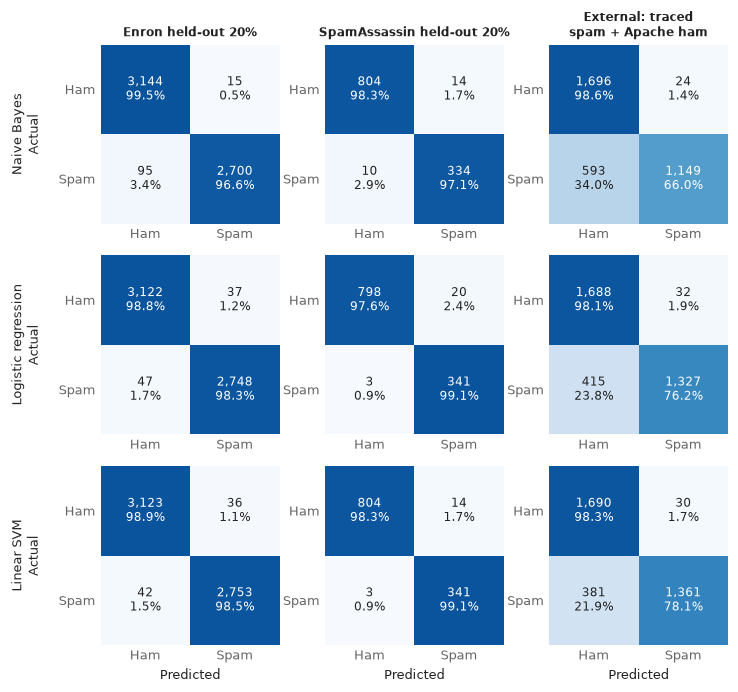

In [26]:
# Figure: confusion matrices, 3 models (rows) x 3 evaluations (columns).
fig, axes = plt.subplots(3, 3, figsize=(7.4, 7.0))
for row_number, model_name in enumerate(MODELS):
    for col_number, (title, key) in enumerate(EVALS):
        ax = axes[row_number, col_number]
        if key:   # held-out part
            r = heldout[(heldout.model == model_name) & (heldout.test == key)].iloc[0]
            counts = np.array([[r.tn, r.fp], [r.fn, r.tp]])
        else:     # external data
            r = primary_external.loc[model_name]
            counts = np.array([[r.TN, r.FP], [r.FN, r.TP]])
        draw_confusion(ax, counts, font_size=8.5)
        if row_number == 0:
            ax.set_title(title, fontsize=8.5, fontweight="bold")
        if col_number == 0:
            ax.set_ylabel(f"{LABEL[model_name]}\nActual", labelpad=12)
        if row_number == 2:
            ax.set_xlabel("Predicted")
save(fig, "eval_confusion.png")

### 9.3 ROC Curves
Draws the ROC curve of each model on the three evaluations and saves `eval_roc.png`.

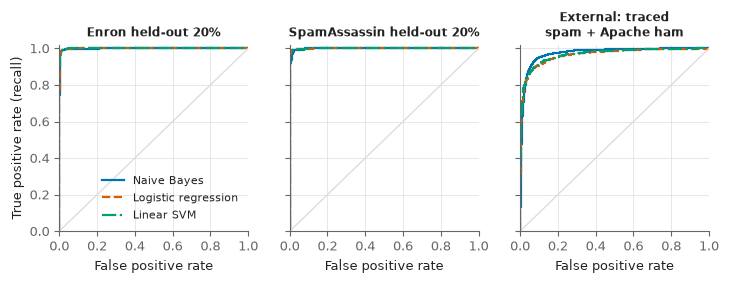

In [27]:
# Figure: ROC curves. Each curve shows, for every possible cut-off, the share of spam caught (up)
# against the share of ham wrongly flagged (right). A curve hugging the top-left corner is better.
fig, axes = plt.subplots(1, 3, figsize=(7.4, 2.9), sharey=True)
for ax, (title, key) in zip(axes, EVALS):
    for model_name in MODELS:
        if key:
            rows = held_scores[(held_scores.model == model_name) & (held_scores.test == key)]
            labels, scores = rows.label.values, rows.score.values
        else:
            labels = np.r_[np.ones(len(spam_scores[model_name])), np.zeros(len(ham_scores[model_name, "primary"]))]
            scores = np.r_[spam_scores[model_name], ham_scores[model_name, "primary"]]
        false_positive_rate, true_positive_rate, _ = roc_curve(labels, scores)
        ax.plot(false_positive_rate, true_positive_rate, LINE_STYLE[model_name], color=COLOUR[model_name], lw=1.6, label=LABEL[model_name])
    ax.plot([0, 1], [0, 1], color=GRID, lw=1)          # the diagonal = guessing
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("False positive rate")
    ax.set_title(title, fontsize=8.5, fontweight="bold")
    ax.grid(color=GRID, lw=0.5)
    ax.set_axisbelow(True)
axes[0].set_ylabel("True positive rate (recall)")
axes[0].legend(frameon=False, loc="lower right", fontsize=8)
save(fig, "eval_roc.png")

### 9.4 Primary Model on External Data
Draws how far each external message lies from the SVM's dividing line, next to its confusion matrix, and saves `test3b_scores_confusion.png`.

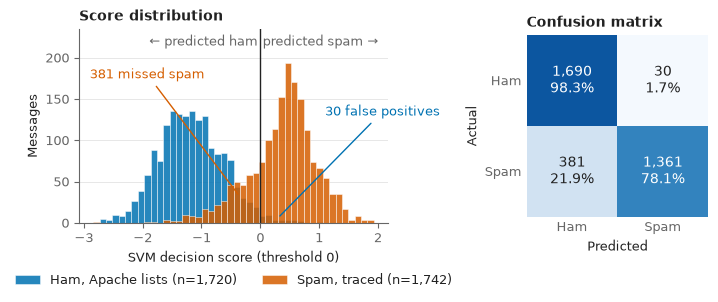

In [28]:
# Figure: the primary model on the external data. Left: how far each message is from the SVM's dividing line.
# Right: the resulting confusion matrix.
spam_svm_scores, ham_svm_scores = spam_scores[PRIMARY], ham_scores[PRIMARY, "primary"]
tp_count, fn_count = int((spam_svm_scores > 0).sum()), int((spam_svm_scores <= 0).sum())
fp_count, tn_count = int((ham_svm_scores > 0).sum()), int((ham_svm_scores <= 0).sum())

fig, (ax_scores, ax_matrix) = plt.subplots(1, 2, figsize=(7.2, 3.2), gridspec_kw={"width_ratios": [1.7, 1]})
bins = np.linspace(min(spam_svm_scores.min(), ham_svm_scores.min()), max(spam_svm_scores.max(), ham_svm_scores.max()), 45)
ax_scores.hist(ham_svm_scores, bins, color=BLUE, alpha=0.85, label=f"Ham, Apache lists (n={len(ham_svm_scores):,})", edgecolor="white", linewidth=0.4)
ax_scores.hist(spam_svm_scores, bins, color=VERMILION, alpha=0.85, label=f"Spam, traced (n={len(spam_svm_scores):,})", edgecolor="white", linewidth=0.4)
ax_scores.axvline(0, color=INK, lw=1)                      # the decision threshold
ax_scores.set_ylim(0, 235)
ax_scores.text(0.04, 228, "predicted spam →", ha="left", va="top", color=MUTED)
ax_scores.text(-0.04, 228, "← predicted ham", ha="right", va="top", color=MUTED)
ax_scores.annotate(f"{fn_count} missed spam", xy=(-0.35, 32), xytext=(-2.9, 175), color=VERMILION, arrowprops=dict(arrowstyle="-", color=VERMILION))
ax_scores.annotate(f"{fp_count} false positives", xy=(0.3, 6), xytext=(1.1, 130), color=BLUE, arrowprops=dict(arrowstyle="-", color=BLUE))
ax_scores.set_xlabel("SVM decision score (threshold 0)")
ax_scores.set_ylabel("Messages")
ax_scores.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
ax_scores.set_title("Score distribution", loc="left", fontweight="bold", fontsize=10)
ax_scores.grid(axis="y", color=GRID, lw=0.5)
ax_scores.set_axisbelow(True)

draw_confusion(ax_matrix, np.array([[tn_count, fp_count], [fn_count, tp_count]]), font_size=10)
ax_matrix.set_xlabel("Predicted")
ax_matrix.set_ylabel("Actual")
ax_matrix.set_title("Confusion matrix", loc="left", fontweight="bold", fontsize=10)
save(fig, "test3b_scores_confusion.png")

### 9.5 Specificity per Mailing List
Draws the specificity of the primary model for each Apache list with 95% Wilson intervals and saves `test3b_specificity.png`.

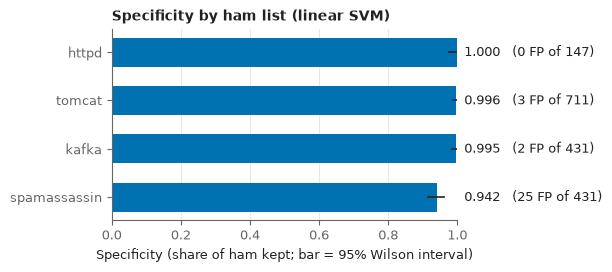

In [29]:
# Figure: specificity (share of ham left alone) for each Apache mailing list, with 95% Wilson intervals.
specificity_by_list = by_group[(by_group.model == PRIMARY) & (by_group.kind == "specificity")].sort_values("rate")
fig, ax = plt.subplots(figsize=(6.4, 2.9))
for position, row in enumerate(specificity_by_list.itertuples()):
    ax.barh(position, row.rate, color=BLUE, height=0.6)
    ax.plot([row.wilson_lo, row.wilson_hi], [position, position], color=INK, lw=1.2)      # the interval
    ax.text(1.02, position, f"{row.rate:.3f}   ({row.n - row.correct} FP of {row.n})", va="center", color=INK)
ax.set_yticks(range(len(specificity_by_list)), list(specificity_by_list.group))
ax.set_xlim(0, 1)
ax.set_xlabel("Specificity (share of ham kept; bar = 95% Wilson interval)")
ax.grid(axis="x", color=GRID, lw=0.5)
ax.set_axisbelow(True)
ax.set_title("Specificity by ham list (linear SVM)", loc="left", fontweight="bold", fontsize=10)
fig.subplots_adjust(left=0.2, right=0.74, bottom=0.22)       # leave room on the right for the labels
if WRITE:
    fig.savefig(FIGS / "test3b_specificity.png", dpi=200)
plt.show()

## 10. Evasion Demonstration (Attacker View)

**The question:** how easily can an attacker change a spam message so that a filter that caught it now misses it?

**How the experiment works.** We make **modified copies** of the 1,742 traced spam (starting from the text *before* masking) and ask the saved models again. The models are not retrained and the threshold is not changed. All randomness is seeded. The attacks, the metrics and the defender step were declared in the project notes (not in this repo) before this section was run.

| Attack | What it does | What the attacker needs to know |
|---|---|---|
| **G-k** | append *k* harmless words (10, 25, 50, 100) taken from words common in legitimate mail | black-box: the word list comes from the **training** split only |
| **G-w** | append the *k* (10, 25, 50) most ham-indicative words of the attacked model's own vocabulary | white-box upper bound: the attacker can see inside the model |
| **D** | append one random legitimate message from the training split | black-box |
| **O1** | swap letters for Cyrillic look-alikes (a c e o p x y) in 30% / 100% of the words | nothing |
| **O2** | hide a zero-width space inside 30% / 100% of the words | nothing |
| **O3** | leetspeak (a to 4, e to 3, i to 1, o to 0, s to 5) in 30% / 100% of the words | nothing |

**Measures.**
* **Evasion rate** (the column is called `flip_rate` in the saved tables) = of the spam a model caught at baseline, the share it misses after the attack. Higher = the attack works better.
* **Recall under attack** = recall over all 1,742 spam.
* Intervals are cluster-bootstrap (campaigns resampled, 1,000 resamples).

**Defender step.** `normalise()` runs *before* masking. It deletes zero-width characters, maps Cyrillic look-alikes back to Latin letters and undoes leetspeak only inside words that mix letters and digits. We report it on the attacked text, and also on *unattacked* spam and on ham, because a defence that hurts clean mail is not a defence.

### 10.1 Attack Characters
Defines the zero-width space, the Cyrillic look-alike map and the leetspeak maps used by the attacks and by the defence.

In [30]:
# --- Characters used by the obfuscation attacks (written as escapes so they are visible in the code) ---
ZERO_WIDTH_SPACE = "​"          # an invisible character

# Latin letter -> a Cyrillic letter that looks (almost) identical on screen.
HOMOGLYPHS = {"a": "а", "c": "с", "e": "е", "o": "о", "p": "р", "x": "х", "y": "у",
              "A": "А", "C": "С", "E": "Е", "O": "О", "P": "Р", "X": "Х", "Y": "У"}
TO_HOMOGLYPH = str.maketrans(HOMOGLYPHS)                                          # Latin -> Cyrillic (the attack)
TO_LATIN = {ord(cyrillic): latin for latin, cyrillic in HOMOGLYPHS.items()}       # Cyrillic -> Latin (the defence)

TO_LEET = str.maketrans("aeiosAEIOS", "4310543105")        # a->4, e->3, i->1, o->0, s->5 (the attack)
FROM_LEET = str.maketrans("43105", "aeios")                # and back (used by the defence)

### 10.2 The Attacker's Word List

For attacks G-k, the attacker needs harmless-looking words. We give them a *realistic* list: words that are common in legitimate training mail (in at least 1% of ham emails) and at least twice as common in ham as in spam, with the source-artefact words removed. The 300 most frequent are kept. **Only the training split is used**, so the attacker does not see the external data.

In [31]:
# Count word frequencies in the training ham and spam (only words of 3+ letters that appear in at least 20 emails).
benign_vectorizer = CountVectorizer(binary=True, min_df=20, token_pattern=r"(?u)\b[a-z]{3,}\b").fit(train["clean"])
train_vocabulary = np.array(benign_vectorizer.get_feature_names_out())
train_ham, train_spam = train[train.label == 0], train[train.label == 1]
ham_frequency = np.asarray(benign_vectorizer.transform(train_ham["clean"]).sum(axis=0)).ravel() / len(train_ham)
spam_frequency = np.asarray(benign_vectorizer.transform(train_spam["clean"]).sum(axis=0)).ravel() / len(train_spam)

is_candidate = ((ham_frequency >= 0.01)                                              # common enough in ham
                & ((ham_frequency + 1e-6) / (spam_frequency + 1e-6) >= 2)            # at least twice as common in ham as in spam
                & ~np.isin(train_vocabulary, SOURCE_ARTEFACTS))                      # and not a source artefact
BENIGN = train_vocabulary[is_candidate][np.argsort(-ham_frequency[is_candidate])][:300]   # the 300 most frequent
print(f"{is_candidate.sum()} candidate benign words; the attacker list has {len(BENIGN)} (top by ham frequency)")
print("first 15:", ", ".join(BENIGN[:15]))

589 candidate benign words; the attacker list has 300 (top by ham frequency)
first 15: subject, would, thanks, know, let, group, date, questions, call, original, forwarded, week, think, following, file


### 10.3 The Attack Functions

Each function takes a list of texts and returns modified copies. Each makes its own random generator from a fixed seed, so the same call always gives the same result.

#### 10.3.1 Attack Functions

In [32]:
def append_benign(texts, k, seed=SEED):
    """G-k: add k random harmless words (from the attacker's list) to the end of every text."""
    generator = np.random.default_rng(seed)
    return [text + " " + " ".join(generator.choice(BENIGN, k, replace=False)) for text in texts]


def ham_words(model, k):
    """G-w (white-box): the k plain words the attacked model considers the strongest evidence of ham."""
    tfidf, classifier = model.named_steps["tfidf"], model.named_steps["clf"]
    if hasattr(classifier, "feature_log_prob_"):      # Naive Bayes: how much likelier is the word in spam than in ham?
        word_weight = classifier.feature_log_prob_[1] - classifier.feature_log_prob_[0]
    else:                                             # logistic regression / SVM: the learned weight
        word_weight = classifier.coef_[0]
    words = tfidf.get_feature_names_out()
    plain_words = [w for w in words[np.argsort(word_weight)] if w.isalpha() and w.isascii() and len(w) >= 3]
    return plain_words[:k]


def dilute(texts, seed=SEED):
    """D: append one whole legitimate message (300 to 3,000 characters, from the training ham) to every text."""
    generator = np.random.default_rng(seed)
    pool = train_ham["text"][train_ham["text"].str.len().between(300, 3000)].values
    return [text + " " + pool[generator.integers(len(pool))] for text in texts]


def perturb(texts, change_word, share, seed=SEED):
    """O1-O3: apply `change_word` to a random `share` of the words that have 4 or more letters."""
    generator = np.random.default_rng(seed)
    def maybe_change(match):
        word = match.group(0)
        return change_word(word) if generator.random() < share else word
    return [re.sub(r"[A-Za-z]{4,}", maybe_change, text) for text in texts]


def to_homoglyphs(word):
    return word.translate(TO_HOMOGLYPH)


def add_zero_width_space(word):
    middle = len(word) // 2
    return word[:middle] + ZERO_WIDTH_SPACE + word[middle:]


def to_leetspeak(word):
    return word.translate(TO_LEET)

#### 10.3.2 What the Obfuscation Attacks Look Like

In [33]:
# What do the obfuscation attacks look like? (the homoglyph version looks the same to a human but is different text)
demo = "Verify your account password immediately"
print("original  :", demo)
print("homoglyph :", perturb([demo], to_homoglyphs, 1.0)[0], "  <- looks identical, but the letters are Cyrillic")
print("zero-width:", repr(perturb([demo], add_zero_width_space, 1.0)[0]), "  <- repr() reveals the hidden characters")
print("leetspeak :", perturb([demo], to_leetspeak, 1.0)[0])

original  : Verify your account password immediately
homoglyph : Vеrifу уоur ассоunt раsswоrd immеdiаtеlу   <- looks identical, but the letters are Cyrillic
zero-width: 'Ver\u200bify yo\u200bur acc\u200bount pass\u200bword immed\u200biately'   <- repr() reveals the hidden characters
leetspeak : V3r1fy y0ur 4cc0unt p455w0rd 1mm3d14t3ly


### 10.4 The Defender Step

`normalise()` undoes the obfuscation so the model sees plain text again. The leetspeak rule is deliberately careful: it only changes a word that contains *both* letters and digits, and no more than half digits, so ordinary numbers and codes are left alone.

In [34]:
def normalise(text):
    """Defender step: delete zero-width characters, map Cyrillic look-alikes to Latin, undo leetspeak inside mixed letter-digit words."""
    text = text.replace(ZERO_WIDTH_SPACE, "").translate(TO_LATIN)

    def undo_leetspeak(match):
        word = match.group(0)
        digits = sum(ch.isdigit() for ch in word)
        has_letters = any(ch.isalpha() for ch in word)
        if 0 < digits <= len(word) // 2 and has_letters:     # a mix of letters and digits, mostly letters
            return word.translate(FROM_LEET)
        return word                                           # leave pure words and pure numbers alone

    return re.sub(r"\w+", undo_leetspeak, text)


# The defence in action on the demo text:
normalise(perturb([demo], to_leetspeak, 1.0)[0]), normalise(perturb([demo], to_homoglyphs, 1.0)[0])

('Verify your account password immediately',
 'Verify your account password immediately')

### 10.5 The List of Experiments

Each condition has a label, an attack family and a parameter (number of words, or share of words changed).

In [35]:
SPAM_TEXT = spam_ext["text"].tolist()     # the 1,742 unmasked spam texts that the attacks start from

# Build the list of conditions: (label, family, parameter).
CONDITIONS = []
for k in (10, 25, 50, 100):
    CONDITIONS.append((f"G-{k}: {k} benign words", "G", k))
for k in (10, 25, 50):
    CONDITIONS.append((f"G-w{k}: model's {k} ham words", "G-w", k))
CONDITIONS.append(("D: ham message appended", "D", 1))
for family, name in (("O1", "homoglyphs"), ("O2", "zero-width space"), ("O3", "leetspeak")):
    for share in (0.3, 1.0):
        CONDITIONS.append((f"{family}: {name} {int(share * 100)}%", family, share))

CHANGE_WORD = {"O1": to_homoglyphs, "O2": add_zero_width_space, "O3": to_leetspeak}


def attacked_texts(family, parameter, model_name):
    """The 1,742 spam texts after one attack. Only G-w depends on the model (it reads the model's own weights)."""
    if family == "G":
        return append_benign(SPAM_TEXT, parameter)
    if family == "G-w":
        words = " ".join(ham_words(models[model_name], parameter))
        return [text + " " + words for text in SPAM_TEXT]
    if family == "D":
        return dilute(SPAM_TEXT)
    return perturb(SPAM_TEXT, CHANGE_WORD[family], parameter)      # O1, O2, O3


print(len(CONDITIONS), "attack conditions x", len(models), "models")

14 attack conditions x 3 models


### 10.6 Running Every Experiment

For each condition and each model we record how many caught spam were flipped to "ham", with and without the defender step. The intervals use 1,000 cluster-bootstrap resamples that are drawn once and shared by every condition.

#### 10.6.1 Run All Attacks

In [36]:
# 1,000 bootstrap resamples of the spam campaigns, drawn once (same RNG recipe as before so results are reproducible).
boot_generator = np.random.default_rng(SEED)
BOOT = [np.concatenate([spam_groups[i] for i in boot_generator.integers(0, len(spam_groups), len(spam_groups))])
        for _ in range(1000)]


def interval(values):
    """The middle 95% of a list of bootstrap results."""
    return np.percentile(values, [2.5, 97.5]).round(4)


evasion_rows = []
for label, family, parameter in CONDITIONS:
    model_specific = (family == "G-w")
    if not model_specific:                       # same attacked text for all three models: build it once
        shared = attacked_texts(family, parameter, None)
        shared_normalised = [normalise(t) for t in shared]

    for model_name, model in models.items():
        if model_specific:
            texts = attacked_texts(family, parameter, model_name)
            texts_normalised = [normalise(t) for t in texts]
        else:
            texts, texts_normalised = shared, shared_normalised

        predicted = model.predict(pd.Series(texts).map(mask))                       # after the attack
        predicted_defended = model.predict(pd.Series(texts_normalised).map(mask))   # after attack + normalise()
        baseline = spam_pred[model_name]                                            # before the attack

        # A "flip" = caught at baseline, missed now.
        flipped = (baseline == 1) & (predicted == 0)
        flipped_defended = (baseline == 1) & (predicted_defended == 0)

        flip_boot = np.array([flipped[rows].sum() / baseline[rows].sum() for rows in BOOT])
        flip_defended_boot = np.array([flipped_defended[rows].sum() / baseline[rows].sum() for rows in BOOT])
        recall_boot = np.array([predicted[rows].mean() for rows in BOOT])

        evasion_rows.append(dict(
            model=model_name, condition=label, family=family, param=parameter,
            caught_at_baseline=int(baseline.sum()), flipped=int(flipped.sum()),
            flip_rate=round(flipped.sum() / baseline.sum(), 4), flip_lo=interval(flip_boot)[0], flip_hi=interval(flip_boot)[1],
            recall_under_attack=round(predicted.mean(), 4), recall_lo=interval(recall_boot)[0], recall_hi=interval(recall_boot)[1],
            flip_rate_after_normalising=round(flipped_defended.sum() / baseline.sum(), 4),
            flip_def_lo=interval(flip_defended_boot)[0], flip_def_hi=interval(flip_defended_boot)[1]))
evasion = pd.DataFrame(evasion_rows)

#### 10.6.2 Effect of Normalising on Clean Mail

In [37]:
# Does normalising hurt clean mail? Score the UNATTACKED spam and the ham after normalise() as well.
spam_normalised = pd.Series([normalise(t) for t in SPAM_TEXT]).map(mask)
ham_normalised = ham_ext["text"].map(normalise).map(mask)
clean_effect = pd.DataFrame([
    dict(model=name,
         recall_before=round(spam_pred[name].mean(), 4),
         recall_after_normalising=round(model.predict(spam_normalised).mean(), 4),
         specificity_before=round(1 - ham_pred[name, "primary"].mean(), 4),
         specificity_after_normalising=round(1 - model.predict(ham_normalised).mean(), 4))
    for name, model in models.items()])

# Safety net: the first run saved these tables; later runs must reproduce them.
saved_evasion, saved_clean = RESULTS / "evasion_results.csv", RESULTS / "evasion_normalise_effect.csv"
if saved_evasion.exists() and not RETRAIN:
    pd.testing.assert_frame_equal(evasion, pd.read_csv(saved_evasion), check_dtype=False, atol=1e-6)
    pd.testing.assert_frame_equal(clean_effect, pd.read_csv(saved_clean), check_dtype=False, atol=1e-6)
    print("evasion results reproduce the saved run")
elif WRITE:
    evasion.to_csv(saved_evasion, index=False)
    clean_effect.to_csv(saved_clean, index=False)
    print("evasion results written (first run)")

evasion results reproduce the saved run


### 10.7 Reading the Results

* **Evasion rate** (first table): how often each attack turns a caught spam into a missed one. Padding with harmless words (G) works very well; look at how the evasion rate climbs with *k*.
* **Recall under attack** (second table): what is left of the model's recall.
* **After normalising** (third table): the obfuscation attacks (O1-O3) are largely undone by `normalise()`. It cannot help against padding, because padding is genuine plain text.
* **Effect on clean mail** (last table): a defence is only useful if it does not hurt normal mail.

#### 10.7.1 Evasion Rate

In [38]:
condition_order = [label for label, _, _ in CONDITIONS]
print("Evasion rate (share of caught spam that is now missed):")
evasion.pivot(index="condition", columns="model", values="flip_rate").reindex(condition_order).round(3)

Evasion rate (share of caught spam that is now missed):


model,LinearSVM,LogReg,NaiveBayes
condition,,,
G-10: 10 benign words,0.317,0.348,0.158
G-25: 25 benign words,0.796,0.812,0.331
G-50: 50 benign words,0.986,0.993,0.614
G-100: 100 benign words,1.000,1.000,0.908
G-w10: model's 10 ham words,0.872,0.783,0.660
G-w25: model's 25 ham words,0.996,0.997,0.974
G-w50: model's 50 ham words,1.000,1.000,0.994
D: ham message appended,0.898,0.891,0.928
O1: homoglyphs 30%,0.074,0.066,0.068


#### 10.7.2 Recall Under Attack

In [39]:
print("Recall under attack (all 1,742 spam):")
evasion.pivot(index="condition", columns="model", values="recall_under_attack").reindex(condition_order).round(3)

Recall under attack (all 1,742 spam):


model,LinearSVM,LogReg,NaiveBayes
condition,,,
G-10: 10 benign words,0.533,0.497,0.555
G-25: 25 benign words,0.160,0.144,0.441
G-50: 50 benign words,0.011,0.005,0.255
G-100: 100 benign words,0.000,0.000,0.061
G-w10: model's 10 ham words,0.100,0.165,0.224
G-w25: model's 25 ham words,0.003,0.002,0.017
G-w50: model's 50 ham words,0.000,0.000,0.004
D: ham message appended,0.080,0.083,0.048
O1: homoglyphs 30%,0.740,0.735,0.636


#### 10.7.3 Evasion Rate After Normalising

In [40]:
print("Evasion rate AFTER normalising the attacked text (obfuscation attacks only):")
obfuscation = evasion[evasion.family.isin(["O1", "O2", "O3"])]
obfuscation.pivot(index="condition", columns="model", values="flip_rate_after_normalising").round(3)

Evasion rate AFTER normalising the attacked text (obfuscation attacks only):


model,LinearSVM,LogReg,NaiveBayes
condition,,,
O1: homoglyphs 100%,0.005,0.005,0.038
O1: homoglyphs 30%,0.005,0.005,0.038
O2: zero-width space 100%,0.005,0.005,0.038
O2: zero-width space 30%,0.005,0.005,0.038
O3: leetspeak 100%,0.037,0.044,0.076
O3: leetspeak 30%,0.016,0.016,0.051


#### 10.7.4 Effect on Clean Mail

In [41]:
print("Effect of normalising on clean (unattacked) mail:")
clean_effect

Effect of normalising on clean (unattacked) mail:


,model,recall_before,recall_after_normalising,specificity_before,specificity_after_normalising
0,NaiveBayes,0.6596,0.6355,0.9860,0.9855
1,LogReg,0.7618,0.7600,0.9814,0.9820
2,LinearSVM,0.7813,0.7801,0.9826,0.9831


#### 10.7.5 Evasion Figure
Draws padding (A) and character tricks (B) and saves `evasion_flip_rates.png` (report Figure 8).

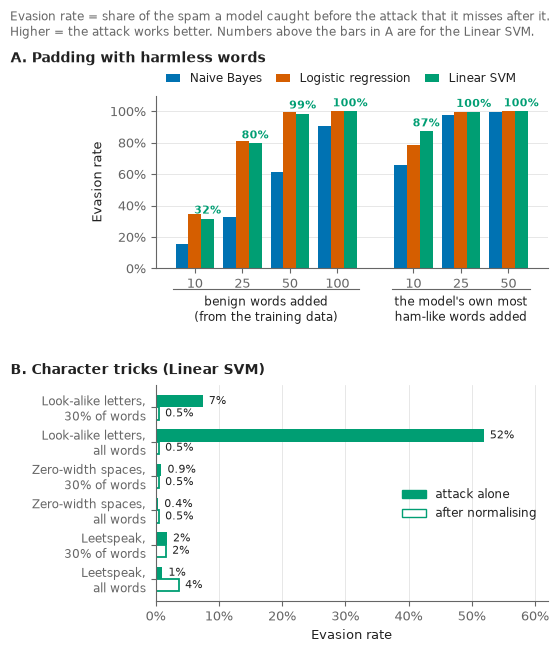

In [42]:
# Figure: evasion rate = share of the spam a model caught before the attack that it misses after it (higher = the attack works better).
# Drawn at about the width it is printed (5.6 in) so the text stays readable. Top, A: padding, one bar per model; the number above
# each group is the Linear SVM's. Bottom, B: character tricks for the primary model, attack alone vs after the normalising step.
from matplotlib.patches import Patch
percent = lambda value: f"{value:.0%}" if value >= 0.01 else f"{value:.1%}"        # 0.5% instead of 0%

fig, (ax_pad, ax_char) = plt.subplots(2, 1, figsize=(5.6, 6.4), gridspec_kw={"height_ratios": [1.0, 1.25]})

# ---- A: padding. Seven groups: 4 amounts of benign words, then 3 amounts of the model's own most ham-like words.
GROUPS = [("G", 10), ("G", 25), ("G", 50), ("G", 100), ("G-w", 10), ("G-w", 25), ("G-w", 50)]
centres = [0, 1, 2, 3, 4.6, 5.6, 6.6]
width = 0.27
for step, model_name in enumerate(MODELS):
    heights = [evasion[(evasion.model == model_name) & (evasion.family == family) & (evasion.param == amount)].flip_rate.iloc[0]
               for family, amount in GROUPS]
    ax_pad.bar([c + (step - 1) * width for c in centres], heights, width=width, color=COLOUR[model_name], label=LABEL[model_name])
    if model_name == PRIMARY:
        for centre, height in zip(centres, heights):
            ax_pad.text(centre + width, height + 0.015, percent(height), ha="center", va="bottom", fontsize=8, fontweight="bold", color=COLOUR[PRIMARY])
ax_pad.set_xticks(centres, [str(amount) for _, amount in GROUPS], fontsize=9)
ax_pad.set_ylim(0, 1.1)
ax_pad.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax_pad.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
ax_pad.tick_params(axis="y", labelsize=9)
ax_pad.set_ylabel("Evasion rate", fontsize=9)
ax_pad.set_title("A. Padding with harmless words", x=-0.37, ha="left", fontweight="bold", fontsize=10, pad=24)
ax_pad.grid(axis="y", color=GRID, lw=0.5)
ax_pad.set_axisbelow(True)
ax_pad.legend(frameon=False, fontsize=8.5, loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=3, columnspacing=1.2, handlelength=1.2)
for first, last, caption in ((0, 3, "benign words added\n(from the training data)"), (4, 6, "the model's own most\nham-like words added")):
    left, right = centres[first] - 0.45, centres[last] + 0.45
    ax_pad.plot([left, right], [-0.12, -0.12], color=MUTED, lw=0.8, clip_on=False, transform=ax_pad.get_xaxis_transform())
    ax_pad.text((left + right) / 2, -0.15, caption, ha="center", va="top", fontsize=8.5, color=INK, transform=ax_pad.get_xaxis_transform())

# ---- B: character tricks, Linear SVM only (the other models behave the same way: see results/evasion_results.csv).
CHARACTER = [("O1", 0.3, "Look-alike letters, 30% of words"), ("O1", 1.0, "Look-alike letters, all words"),
             ("O2", 0.3, "Zero-width spaces, 30% of words"), ("O2", 1.0, "Zero-width spaces, all words"),
             ("O3", 0.3, "Leetspeak, 30% of words"), ("O3", 1.0, "Leetspeak, all words")]
positions = np.arange(len(CHARACTER))[::-1]
bar = 0.36
for position, (family, share, _) in zip(positions, CHARACTER):
    row = evasion[(evasion.model == PRIMARY) & (evasion.family == family) & (evasion.param == share)].iloc[0]
    for shift, value, style in ((bar / 2, row.flip_rate, dict(color=COLOUR[PRIMARY])),
                                (-bar / 2, row.flip_rate_after_normalising, dict(facecolor="white", edgecolor=COLOUR[PRIMARY], linewidth=1.3))):
        ax_char.barh(position + shift, value, height=bar, **style)
        ax_char.text(value + 0.01, position + shift, percent(value), va="center", fontsize=8, color=INK)
ax_char.set_yticks(positions, [label.replace(", ", ",\n") for _, _, label in CHARACTER], fontsize=8.5)
ax_char.set_xlim(0, 0.62)
ax_char.xaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
ax_char.tick_params(axis="x", labelsize=9)
ax_char.set_xlabel("Evasion rate", fontsize=9)
ax_char.set_title("B. Character tricks (Linear SVM)", x=-0.37, ha="left", fontweight="bold", fontsize=10, pad=8)
ax_char.grid(axis="x", color=GRID, lw=0.5)
ax_char.set_axisbelow(True)
ax_char.legend(handles=[Patch(color=COLOUR[PRIMARY], label="attack alone"), Patch(facecolor="white", edgecolor=COLOUR[PRIMARY], label="after normalising")],
               frameon=False, fontsize=8.5, loc="center right", bbox_to_anchor=(1.0, 0.45))

fig.text(0.01, 0.995, "Evasion rate = share of the spam a model caught before the attack that it misses after it.\nHigher = the attack works better. Numbers above the bars in A are for the Linear SVM.",
         ha="left", va="top", fontsize=8.5, color=MUTED)
fig.subplots_adjust(left=0.27, right=0.97, top=0.86, bottom=0.07, hspace=0.6)
if WRITE:
    fig.savefig(FIGS / "evasion_flip_rates.png", dpi=200)
plt.show()

## 11. Summary

The two evaluations side by side for each model. Held-out numbers are in-distribution (same sources as training); external numbers are the traced spam plus the Apache ham. Details, intervals and per-source tables are in sections 5 and 7.

**What to notice:** every model scores about 0.97 to 0.99 F1 on mail like its training data, but its *recall* on the external spam is much lower. A filter that looks excellent on familiar mail can still miss a lot of new spam, which is the main finding of the detection part of the report.

### 11.1 Summary Table
Shows the held-out F1 and the external metrics of each model side by side (report Table 4 and section 3.3).

In [43]:
summary = pd.DataFrame({
    "held-out F1, Enron": heldout[heldout.test == "enron_test"].set_index("model").f1,
    "held-out F1, SpamAssassin": heldout[heldout.test == "sa_test"].set_index("model").f1,
    "external recall": primary_external.recall,
    "external specificity": primary_external.specificity,
    "external precision": primary_external.precision,
    "external F1": primary_external.f1,
    "external AUC": primary_external.auc,
}).round(3)
summary.loc[list(MODELS)]

,"held-out F1, Enron","held-out F1, SpamAssassin",external recall,external specificity,external precision,external F1,external AUC
model,,,,,,,
NaiveBayes,0.980,0.965,0.660,0.986,0.980,0.788,0.974
LogReg,0.985,0.967,0.762,0.981,0.976,0.856,0.965
LinearSVM,0.986,0.976,0.781,0.983,0.978,0.869,0.967
